<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h3 style="text-align: center;"><b>Домашнее задание. Детекция объектов</b></h3>

В этом домашнем задании мы продолжим работу над детектором из семинара, поэтому при необходимости можете заимствовать оттуда любой код.

Домашнее задание можно разделить на следующие части:

* Переделываем модель [4]
  * Backbone[1],
  * Neck [2],
  * Head [1]
* Label assignment [3]:
  * TAL [3]
* Лоссы [1]:
  * CIoU loss [1]
* Кто больше? [5]
  * 0.05 mAP [1]
  * 0.1 mAP  [2]
  * 0.2 mAP [5]

**Максимальный балл:** 10 баллов. (+3 балла бонус).

In [365]:
import torch

import albumentations as A
import torchvision
import torchvision.ops
from PIL import Image
from torchvision import transforms
from albumentations.pytorch.transforms import ToTensorV2

In [366]:
import math
from functools import partial
from collections import Counter, defaultdict

import io
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import timm
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

from PIL import Image
from tqdm.auto import tqdm
from torchvision import transforms
from torchvision.ops import nms, box_iou
from torchvision.models.detection.anchor_utils import AnchorGenerator

from torchmetrics.detection import MeanAveragePrecision

### Загрузка данных

Мы продолжаем работу с датасетом из семинара - Halo infinite ([сслыка](https://universe.roboflow.com/graham-doerksen/halo-infinite-angel-aim)). Загрузка данных и создание датасета полностью скопированы из семинара.

Сначала загружаем данные

In [367]:
splits = {
    'train': r'D:\ML_DLS\Deep_Learning_01\09_detection\source\dataset\halo-infinite-angel-videogame\data\train.parquet',
    'validation': r'D:\ML_DLS\Deep_Learning_01\09_detection\source\dataset\halo-infinite-angel-videogame\data\validation.parquet',
    'test': r'D:\ML_DLS\Deep_Learning_01\09_detection\source\dataset\halo-infinite-angel-videogame\data\test.parquet'
}

df_train = pd.read_parquet(splits['train'])
df_val   = pd.read_parquet(splits['validation'])
df_test  = pd.read_parquet(splits['test'])

Создаем датасет для предобработки данных

In [368]:
class HaloDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        df_objects = pd.json_normalize(dataframe['objects'])[["bbox", "category"]]
        df_images  = pd.json_normalize(dataframe['image'])[["bytes"]]
        self.data  = dataframe[["image_id"]].join(df_objects).join(df_images)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        image = Image.open(io.BytesIO(row["bytes"]))
        image = np.array(image)

   
        labels = row["category"]
        labels = [l for l in labels if not pd.isna(l)]   # удаляем nan
        labels = [int(l) - 1 for l in labels]            # 1..4 → 0..3
        # ---------------------

        # bbox convert w,h → x1,y1,x2,y2
        boxes = []
        for (x, y, w, h) in row["bbox"]:
            boxes.append([x, y, x + w, y + h])

        if self.transform is not None:
            out = self.transform(image=image, bboxes=boxes, labels=labels)
            image, boxes, labels = out["image"], out["bboxes"], out["labels"]
        else:
            image = ToTensorV2()(image=image)["image"]

        target = {
            "image_id": row["image_id"],
            "boxes":  torch.tensor(boxes, dtype=torch.float32),
            "labels": torch.tensor(labels, dtype=torch.int64)
        }

        return image, target


def collate_fn(batch):
    imgs, targets = zip(*batch)
    imgs = torch.stack(imgs)
    return imgs, list(targets)


Чтобы модель не переобучалась, можно добавить больше аугментаций, весь список можно посмотреть тут [[ссылка](https://explore.albumentations.ai/)].

Какие можно использовать аугментации?
* Добавить зум `RandomResizedCrop`,
* Сделать цветовые аугментации типа `RandomBrightnessContrast` и/или `HueSaturationValue`,
* Добавить шум `GaussNoise`,
* Вырезать случайные части изображения `CoarseDropout`,
* И любые другие!

Аугментации можно комбинировать посредствам `A.OneOf`, `A.SomeOf` или `A.RandomOrder`.

Хоть аугментации ограничиваются только вашей фантазией, перед обучением советуем посмотреть на результат преобразований и убедиться, что изображение ещё поддается детекции:)

In [369]:
import albumentations as A
from albumentations.pytorch.transforms import ToTensorV2

mean = (0.485, 0.456, 0.406)
std  = (0.229, 0.224, 0.225)

train_transform = A.Compose(
    [
        A.Resize(640, 640),
        A.HorizontalFlip(p=0.5),
        A.RandomBrightnessContrast(p=0.2),
        A.Normalize(mean=mean, std=std),
        ToTensorV2(),
    ],
    bbox_params=A.BboxParams(
        format='pascal_voc',
        min_area=0,
        min_visibility=0,
        label_fields=['labels']
    )
)

test_transform = A.Compose(
    [
        A.Resize(640, 640),
        A.Normalize(mean=mean, std=std),
        ToTensorV2(),
    ],
    bbox_params=A.BboxParams(
        format='pascal_voc',
        label_fields=['labels']
    )
)



Не забываем инициализировать наш датасет

In [370]:
train_dataset = HaloDataset(df_train, transform=train_transform)
val_dataset   = HaloDataset(df_val,   transform=test_transform)
test_dataset  = HaloDataset(df_test,  transform=test_transform)

train_dataloader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    collate_fn=collate_fn
)

val_dataloader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    collate_fn=collate_fn
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    collate_fn=collate_fn
)

## Переделываем модель [4 балла]

В семинаре мы реализовали самый базовый детектор, а сейчас настало время его улучшать. 

### Backbone [1 балл]

Хорошей практикой считается размораживать несколько последних слоев в backbone, это позволяет немного улучить качество модели. Давайте улушчим класс Backbone из лекции, добавив ему возможность разморозки __k__ последних слоев или блоков (на ваш выбор).

In [371]:
import torchvision.models as models
import torch.nn as nn

class backbone(nn.Module):
    def __init__(self, unfreeze_last=0):
        super().__init__()
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

        self.stem = nn.Sequential(
            m.conv1,
            m.bn1,
            m.relu,
            m.maxpool,
        )
        self.layer1 = m.layer1  # C2
        self.layer2 = m.layer2  # C3
        self.layer3 = m.layer3  # C4
        self.layer4 = m.layer4  # C5

        self.out_channels = [512, 1024, 2048]
        # OPTIONAL: заморозка всех слоёв
        if unfreeze_last == 0:
            for p in self.parameters():
                p.requires_grad = False

    def forward(self, x):
        x = self.stem(x)
        c2 = self.layer1(x)
        c3 = self.layer2(c2)
        c4 = self.layer3(c3)
        c5 = self.layer4(c4)
        return [c3, c4, c5]


In [372]:
bb = backbone()
x = torch.randn(1,3,640,640)
feats = bb(x)
print(type(feats), len(feats))
for f in feats:
    print(f.shape)


<class 'list'> 3
torch.Size([1, 512, 80, 80])
torch.Size([1, 1024, 40, 40])
torch.Size([1, 2048, 20, 20])


### NECK [2 балла]

Следующее улучшение коснется шеи. Предлагаем реализовать знакомую из лекции архитектуру FPN.

#### Feature Pyramid Network

<center><img src="https://user-images.githubusercontent.com/57972646/69858594-b14a6c00-12d5-11ea-8c3e-3c17063110d3.png"/></center>


* [Feature Pyramid Networks for Object Detection](https://arxiv.org/abs/1612.03144)

Она состоит из top-down пути, в котором происходит 2 вещи:
1. Увеличивается пространственная размерность фичей,
2. С помощью скипконнекшеннов, добавляются фичи из backbone модели.

Для увеличения пространственной размерности используется __nearest neighbor upsampling__, а фичи из шеи и бекбоуна суммируются.

__TIPS__:
* Можете использовать базовые классы из лекции,
* Воспользуйтесь AnchorGenerator-ом, чтобы создавать якоря сразу для нескольких выходов,
* Не забудьте использовать nn.ModuleList, если захотите сделать динамическое количество голов у модели,
* Также, можно добавить доп конволюцию (3х3 с паддингом) у каждого выхода шеи.

In [373]:
class neck(nn.Module):
    def __init__(self, in_channels=[512, 1024, 2048], out_channels=256):
        super().__init__()

        self.l3 = nn.Conv2d(in_channels[0], out_channels, 1)
        self.l4 = nn.Conv2d(in_channels[1], out_channels, 1)
        self.l5 = nn.Conv2d(in_channels[2], out_channels, 1)

        self.p3 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.p4 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.p5 = nn.Conv2d(out_channels, out_channels, 3, padding=1)

        self.p6 = nn.Conv2d(out_channels, out_channels, 3, stride=2, padding=1)

        self.up = nn.Upsample(scale_factor=2, mode='nearest')

    def forward(self, feats):
        c3, c4, c5 = feats
    
        t5 = self.l5(c5)
        t4 = self.l4(c4) + self.up(t5)
        t3 = self.l3(c3) + self.up(t4)
    
        p3 = self.p3(t3)
        p4 = self.p4(t4)
        p5 = self.p5(t5)
    
        return [p3, p4, p5]


### Head [1 балл]

В качестве шеи можно выбрать __один из двух__ вариантов:

#### 1. Decoupled Head

Реализовать Decoupled Head из [YOLOX](https://arxiv.org/abs/2107.08430).
<center><img src="https://i.ibb.co/BVtBR2R3/Decoupled-head.jpg"/></center>

**TIP**: Возьмите за основу голову из семинара, тк она сильно похожа на Decoupled Head.

Изменять количество параметров у шей на разных уровнях не обязательно.

#### 2. Confidence score free head

Нужно взять за основу голову из семинара и полностью убрать предсказание confidence score. Чтобы модель предсказывала только 2 группы: ббоксы и классы.

Есть следующие способы удаления confidence score:
* Добавление нового класса ФОН. Обычно его обозначают нулевым классом.
* Присваивание ббоксам БЕЗ объекта вектор из нулей в качестве таргета.

Выберете тот, который вам больше нравится и будте внимательны при расчете лосса! 

**Важно!** Удаление confidence score повлияет на следующие методы из семинара:
* target_assign
* ComputeLoss
* _filter_predictions

In [374]:
import torch
import torch.nn as nn

class head(nn.Module):
    def __init__(self, channels=256, num_classes=1):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.ReLU(inplace=True),
        )

        # bbox регрессия → t_x, t_y, t_w, t_h
        self.box_out = nn.Conv2d(channels, 4, 3, padding=1)

        # классификация → num_classes логитов
        self.cls_out = nn.Conv2d(channels, num_classes, 3, padding=1)

        # инициализация как в retinanet (важно!)
        nn.init.normal_(self.box_out.weight, std=0.01)
        nn.init.constant_(self.box_out.bias, 0)

        nn.init.normal_(self.cls_out.weight, std=0.01)
        nn.init.constant_(self.cls_out.bias, -2.0)

    def forward(self, feats):
        box_preds = []
        cls_preds = []

        for f in feats:
            t = self.conv(f)
            box_preds.append(self.box_out(t))  # [B,4,H,W]
            cls_preds.append(self.cls_out(t))  # [B,num_classes,H,W]

        return box_preds, cls_preds


Теперь можно снова реализовать класс детектора с учетом всех частей выше!

In [375]:
class detector(nn.Module):
    def __init__(self, backbone, neck, head, anchor_generator):
        super().__init__()
        self.backbone = backbone
        self.neck = neck
        self.head = head
        self.anchor_generator = anchor_generator

    def forward(self, x):
        feats = self.backbone(x)      # [c3,c4,c5]
        feats = self.neck(feats)      # [p3,p4,p5]

        box_preds, cls_preds = self.head(feats)
        anchors_by_lvl = self.anchor_generator(feats)   # список: [B, HW*A,4]

        print("feats:", len(feats))
        print("anchors_by_lvl:", len(anchors_by_lvl))

        all_anchors = []
        all_preds   = []

        B = x.shape[0]
        L = len(feats)

        for lvl in range(L):
            # anchors: [B, HW*A, 4]
            a = anchors_by_lvl[lvl]

            # box: [B, 4, H, W] → [B, HW, 4]
            b = box_preds[lvl].permute(0,2,3,1).reshape(B, -1, 4)

            # cls: [B, C, H, W] → [B, HW, C]
            c = cls_preds[lvl].permute(0,2,3,1).reshape(B, -1, cls_preds[lvl].shape[1])

            # preds lvl: [B, HW, 4+C]
            p = torch.cat([b, c], dim=2)

            all_anchors.append(a)
            all_preds.append(p)

        # теперь склеиваем уровни по axis=1, НО сохраняем batch!
        all_anchors = torch.cat(all_anchors, dim=1)   # [B, TOTAL, 4]
        all_preds   = torch.cat(all_preds,   dim=1)   # [B, TOTAL, 4+C]

        return all_anchors, all_preds


## Label assignment [3 балла]
В этой секции предлагается заменить функцию `assign_target` на более современный алгоритм который называется Task alignment learning.

Он описан в статье [TOOD](https://arxiv.org/abs/2108.07755) в секции 3.2. Для удобства вот его основные шаги:

1. Посчитать значение метрики для каждого предсказанного ббокса:
    
$$t = s^\alpha * u^\beta$$
    
где,
* $s$ — classification score, или вероятность принадлежности предсказанного ббокса к классу реального ббокса (**GT**);
* $u$ — IoU между предсказанным и реальным ббоксами;
* $\alpha,\ \beta$ — нормализационные константы, обычно $\alpha = 6.0, \ \beta = 1.0$.
    
2. Отфильтровать предсказания на основе **GT**.

    Для якорных детекторов, обычно, выбираются только те предсказания, центры якорей которых находятся внутри GT.
4. Для каждого **GT** выбрать несколько (обычно 5 или 13) самых подходящих предсказаний.
5. Если предсказание рассматривается в качестве подходящего для нескольких **GT** — выбрать **GT** с наибольшим пересечением по IoU.


**BAЖНО**: если будете использовать Runner из лекции, не забудьте поменять параметры  в `self.assign_target_method` в методе `_run_train_epoch`.

In [376]:
import torch

def tal_assigner(
        anchors_xyxy,       # [N,4] xyxy в нормализованных координатах
        pred_boxes_cxcywh,  # [N,4] cxcywh нормализованные
        pred_logits,        # [N,C]
        gt_boxes_xyxy,      # [G,4] xyxy норм. координаты
        gt_labels,          # [G]
        alpha=6.0,
        beta=1.0,
        k=5
):
    device = anchors_xyxy.device
    N = anchors_xyxy.size(0)
    G = gt_boxes_xyxy.size(0)

    if G == 0:
        return (
            torch.full((N,), -1, dtype=torch.int64, device=device),
            torch.zeros((N, 4), dtype=torch.float32, device=device),
            torch.zeros(N, dtype=torch.float32, device=device),
        )


    # cxcywh -> xyxy
    def cxcywh_to_xyxy(b):
        cx, cy, w, h = b[:,0], b[:,1], b[:,2], b[:,3]
        x1 = cx - w*0.5
        y1 = cy - h*0.5
        x2 = cx + w*0.5
        y2 = cy + h*0.5
        return torch.stack([x1,y1,x2,y2], dim=1)

    pred_xyxy = cxcywh_to_xyxy(pred_boxes_cxcywh)


    # IoU matrix [N,G]
    l = pred_xyxy.unsqueeze(1)
    g = gt_boxes_xyxy.unsqueeze(0)

    inter_x1 = torch.max(l[...,0], g[...,0])
    inter_y1 = torch.max(l[...,1], g[...,1])
    inter_x2 = torch.min(l[...,2], g[...,2])
    inter_y2 = torch.min(l[...,3], g[...,3])

    inter = (inter_x2 - inter_x1).clamp(0) * (inter_y2 - inter_y1).clamp(0)

    area_l = (l[...,2]-l[...,0]) * (l[...,3]-l[...,1])
    area_g = (g[...,2]-g[...,0]) * (g[...,3]-g[...,1])

    iou = inter / (area_l + area_g - inter + 1e-7)   # [N,G]


    # inside: anchor centers inside GT box
    anc_cx = (anchors_xyxy[:,0] + anchors_xyxy[:,2]) * 0.5
    anc_cy = (anchors_xyxy[:,1] + anchors_xyxy[:,3]) * 0.5

    gx1, gy1, gx2, gy2 = gt_boxes_xyxy[:,0], gt_boxes_xyxy[:,1], gt_boxes_xyxy[:,2], gt_boxes_xyxy[:,3]

    inside = (
        (anc_cx.unsqueeze(1) >= gx1) &
        (anc_cx.unsqueeze(1) <= gx2) &
        (anc_cy.unsqueeze(1) >= gy1) &
        (anc_cy.unsqueeze(1) <= gy2)
    )  # [N,G]


    # classification scores
    cls_prob = pred_logits.softmax(-1)     # [N,C]
    s = cls_prob[:, gt_labels]             # [N,G]

    # final score
    t = (s**alpha) * (iou**beta) * inside.float()

    # ------------------------
    # top-k per GT (НО ТОЛЬКО если есть положительные)
    # ------------------------
    topk_mask = torch.zeros_like(t, dtype=torch.bool)

    for j in range(G):
        vals = t[:, j]
        if vals.max() == 0:
            continue    # нет ни одного inside → нет top-k
        k_ = min(k, (vals>0).sum().item())
        if k_ == 0:
            continue
        _, idx = vals.topk(k_)
        topk_mask[idx, j] = True


    # assign
    assigned = torch.full((N,), -1, dtype=torch.int64, device=device)
    assigned_boxes = torch.zeros((N,4), device=device)
    assigned_scores = torch.zeros(N, device=device)

    for i in range(N):
        mask = topk_mask[i]
        if mask.any():
            iou_i = iou[i] * mask.float()
            j = torch.argmax(iou_i)
            assigned[i] = gt_labels[j]
            assigned_boxes[i] = gt_boxes_xyxy[j]
            assigned_scores[i] = iou_i[j]

    return assigned, assigned_boxes, assigned_scores


### DIoU [1]

Вместо SmoothL1, который используется в семинаре, реализуем лосс, основанный на пересечении ббоксов. В качестве тренировки давайте напишем Distance Intersection over Union (DIoU).

<center><img src=https://wikidocs.net/images/page/163613/Free_Fig_5.png></center>

Для его реализации разобъем задачу на части:

**1. Реализуем IoU:**

Пусть даны координаты для предсказанного ($B^p$) и истинного ($B^g$) ббоксов в формате XYXY или VOC PASCAL (левый верхний и правый нижний углы):

$B^p=(x^p_1, y^p_1, x^p_2, y^p_2)$, $B^g=(x^g_1, y^g_1, x^g_2, y^g_2)$, тогда алгоритм расчета будет следующий:

    1. Найдем площади обоих ббоксов:
$$ A^p = (x^p_2 - x^p_1) * (y^p_2 - y^p_1) $$
$$ A^g = (x^g_2 - x^g_1) * (y^g_2 - y^g_1) $$

    2. Посчитаем пересечение между ббоксами:

Тут мы предлагаем вам подумать как в общем виде можно расчитать размеры ббокса, который будет являться пересечением $B^p$ и $B^g$, а затем посчитать его площадь:

$$x^I_1 = \qquad \qquad y^I_1 = $$
$$x^I_2 = \qquad \qquad y^I_2 = $$

В общем виде, площать будет записываться следующим образом:

Если $x^I_2 > x^I_1$ & $y^I_2 > y^I_1$, тогда:

$$I = (x^I_2 - x^I_1) * (y^I_2 - y^I_1)$$

Иначе, $I = 0$.

    3. Считаем объединение ббоксов.

Мы можем посчитать эту площадь как сумму площадей двух ббоксов минус площадь пересечения (тк мы считаем её два раз в сумме площадей):

$$U = A^p + A^g - I$$

    4. Вычисляем IoU.

$$IoU = \frac{I}{U}$$

**2. Посчитаем диагональ выпуклой оболочки:**

Для расчета диагонали, сначала выпишите координаты верхнего левого и правого нижнего углов. Подумайте, чему будут равны эти координаты в общем случае?

$$x^c_1 = \qquad \qquad y^c_1 = $$
$$x^c_2 = \qquad \qquad y^c_2 = $$

Подсказка: Нарисуйте несколько вариантов пересечений предсказания и GT на бумажке, и выпишите координаты для выпуклой оболочки.

Тогда квадрат диагонали можно посчитать по формуле:

$$c^2 = (x^c_2 - x^c_1)^2 + (y^c_2 - y^c_1)^2$$

**3. Рассчитаем расстояние между цетрами ббоксов:**

Сначала находим координаты центров каждого из ббоксов (если ббоксы в формате YOLO, то и считать ничего не нужно), затем считаем Евклидово расстояние между центрами.

$d = $

Собираем все части вместе и считаем лосс по формуле:

$$ DIoU = 1 - IoU + \frac{d^2}{c^2}$$

Помните, что пар ббоксов может быть много! Возвращайте усредненное значение лосса.

In [377]:
from torchvision.ops import distance_box_iou_loss

In [378]:
def gen_bbox(num_boxes=10):
    min_corner = torch.randint(0, 100, (num_boxes, 2))
    max_corner = torch.randint(50, 150, (num_boxes, 2))

    for i in range(2):
        wrong_order = min_corner[:, i] > max_corner[:, i]
        if wrong_order.any():
            min_corner[wrong_order, i], max_corner[wrong_order, i] = max_corner[wrong_order, i], min_corner[wrong_order, i]
    return torch.cat((min_corner, max_corner), dim=1)        

In [379]:
pred_boxes = gen_bbox(num_boxes=100)
true_boxes = gen_bbox(num_boxes=100)

In [380]:
print(f" DIoU: {distance_box_iou_loss(pred_boxes, true_boxes, reduction="mean").item()}")

 DIoU: 1.0012942552566528


In [381]:
import torch

def diou_loss(pred_boxes, gt_boxes, reduction="mean"):
    x1p, y1p, x2p, y2p = pred_boxes.unbind(-1)
    x1g, y1g, x2g, y2g = gt_boxes.unbind(-1)

    inter_x1 = torch.max(x1p, x1g)
    inter_y1 = torch.max(y1p, y1g)
    inter_x2 = torch.min(x2p, x2g)
    inter_y2 = torch.min(y2p, y2g)

    inter = (inter_x2 - inter_x1).clamp(min=0) * (inter_y2 - inter_y1).clamp(min=0)
    area_p = (x2p - x1p) * (y2p - y1p)
    area_g = (x2g - x1g) * (y2g - y1g)
    union = area_p + area_g - inter
    iou = inter / (union + 1e-7)

    cxp = (x1p + x2p) * 0.5
    cyp = (y1p + y2p) * 0.5
    cxg = (x1g + x2g) * 0.5
    cyg = (y1g + y2g) * 0.5
    d2 = (cxp - cxg)**2 + (cyp - cyg)**2

    x1c = torch.min(x1p, x1g)
    y1c = torch.min(y1p, y1g)
    x2c = torch.max(x2p, x2g)
    y2c = torch.max(y2p, y2g)
    c2 = (x2c - x1c)**2 + (y2c - y1c)**2 + 1e-7

    diou = 1 - iou + d2 / c2

    if reduction == "mean":
        return diou.mean()
    if reduction == "sum":
        return diou.sum()
    return diou


In [382]:
import numpy as np
pred_boxes = gen_bbox(num_boxes=1000)
true_boxes = gen_bbox(num_boxes=1000)

# проверим что написанный лосс выдает те же результаты что и лосс из торча.
assert np.isclose(diou_loss(pred_boxes, true_boxes), distance_box_iou_loss(pred_boxes, true_boxes, reduction="mean"))

## Кто больше? [5 баллов]

Наконец то мы дошли до самый интересной части. Тут мы раздаем очки за mAP'ы!

Все что вы написали выше вам поможет улучшить качество итогового детектора, настало время узнать насколько сильно :)

За достижения порога по mAP на тестовом наборе вы получаете баллы:
* 0.05 mAP [1]
* 0.1 mAP [2]
* 0.2 mAP [5]


**TIPS**:
1. На семинаре мы специально не унифицировали формат ббоксов между методами, чтобы обратить ваше внимание что за этим нужно следить. Чтобы было проще, сразу унифицируете формат по всему ноутбуку. Советуем использовать формат xyxy, тк IoU и NMS из torch используют именно этот формат. (Не забудьте поменять формат у таргета в `HaloDataset`).

2. Попробуйте перейти к IoU-based лоссу при обучении. То есть обучать не смещения, а сразу предсказывать ббокс.

3. Поэксперементируйте с подходами target assignment'а в процессе обучения. Например, можно на первых итерациях использовать обычный метод, а затем подключить TAL.

4. Добавьте аугментаций!

Можно взять [albumentations](https://albumentations.ai/docs/getting_started/bounding_boxes_augmentation/), библиотеку, которую мы использовали всеминаре. Или базовые аугментации из торча [тык](https://pytorch.org/vision/main/transforms.html). Если будете использовать торч, не забудте про ббоксы, transforms из коробки не будет их агументировать.

5. Можете реализовать другую шею, которую мы обсуждали на лекции [Path Aggregation Network](https://arxiv.org/abs/1803.01534) она точно улучшит ваше итоговое качество.

6. Попробуйте добавлять различные блоки из YOLO архитектур в шею вместо единичных конволюционных слоев. (Например, замените конволюции 3х3 на CSP блоки).

7. Попробуйте заменить NMS на другой метод (WeightedNMS, SoftNMS, etc.). Немного ссылок:
    * Статья про SoftNMS [тык](https://arxiv.org/pdf/1704.04503)
    * Статья про WeightedNMS [тык](https://openaccess.thecvf.com/content_ICCV_2017_workshops/papers/w14/Zhou_CAD_Scale_Invariant_ICCV_2017_paper.pdf)
    * Есть их реализация, правда на нумбе [git](https://github.com/ZFTurbo/Weighted-Boxes-Fusion?tab=readme-ov-file)

8. Не бойтесь эксперементировать и удачи!

Также, напишите развернутые ответы на следующие вопросы:

**Questions:**
1. Какой метод label assignment'a помогает лучше обучаться модели? Почему?
2. Какое из сделаных вами улучшений внесло наибольший вклад в качество модели? Как вы думаете, почему это произошло?
3. Какое из сделанных вами улучшений вообще не изменило метрику? Как вы думаете, почему это произошло?

In [383]:
def tal_assigner(anchors_xyxy, pred_boxes_cxcywh, pred_logits,
                 gt_boxes_xyxy, gt_labels, alpha=6.0, beta=1.0, k=5):

    device = anchors_xyxy.device
    N = anchors_xyxy.size(0)
    G = gt_boxes_xyxy.size(0)

    if G == 0:
        return (
            torch.full((N,), -1, dtype=torch.int64, device=device),
            torch.zeros((N, 4), device=device),
            torch.zeros(N, device=device),
        )

    # cxcywh → xyxy
    def cxcywh_to_xyxy(b):
        cx, cy, w, h = b[:,0], b[:,1], b[:,2], b[:,3]
        x1 = cx - w * 0.5
        y1 = cy - h * 0.5
        x2 = cx + w * 0.5
        y2 = cy + h * 0.5
        return torch.stack([x1, y1, x2, y2], dim=1)

    pred_xyxy = cxcywh_to_xyxy(pred_boxes_cxcywh)

    # ---- iou ----
    l = pred_xyxy.unsqueeze(1)  # [N,1,4]
    g = gt_boxes_xyxy.unsqueeze(0)

    inter_x1 = torch.max(l[...,0], g[...,0])
    inter_y1 = torch.max(l[...,1], g[...,1])
    inter_x2 = torch.min(l[...,2], g[...,2])
    inter_y2 = torch.min(l[...,3], g[...,3])

    inter = (inter_x2 - inter_x1).clamp(0) * (inter_y2 - inter_y1).clamp(0)
    area_l = (l[...,2]-l[...,0]) * (l[...,3]-l[...,1])
    area_g = (g[...,2]-g[...,0]) * (g[...,3]-g[...,1])
    iou = inter / (area_l + area_g - inter + 1e-7)

    # ---- inside ----
    anc_cx = (anchors_xyxy[:,0] + anchors_xyxy[:,2]) * 0.5
    anc_cy = (anchors_xyxy[:,1] + anchors_xyxy[:,3]) * 0.5

    x1g, y1g, x2g, y2g = gt_boxes_xyxy.t()

    inside = (
        (anc_cx.unsqueeze(1) >= x1g) &
        (anc_cx.unsqueeze(1) <= x2g) &
        (anc_cy.unsqueeze(1) >= y1g) &
        (anc_cy.unsqueeze(1) <= y2g)
    )

    # ---- classification score ----
    cls_prob = pred_logits.softmax(-1)
    s = cls_prob[:, gt_labels]

    # ---- final score ----
    t = (s ** alpha) * (iou ** beta) * inside.float()

    # ---- top-k selection ----
    topk_mask = torch.zeros_like(t, dtype=torch.bool)
    for gind in range(G):
        vals = t[:, gind]
        if vals.max() == 0:
            continue
        k_ = min(k, (vals > 0).sum().item())
        if k_ == 0:
            continue
        _, idx = vals.topk(k_)
        topk_mask[idx, gind] = True

    # ---- assign ----
    assigned = torch.full((N,), -1, dtype=torch.int64, device=device)
    assigned_boxes = torch.zeros((N,4), device=device)
    assigned_scores = torch.zeros(N, device=device)

    for i in range(N):
        mask = topk_mask[i]
        if mask.any():
            iou_i = iou[i] * mask.float()
            j = torch.argmax(iou_i)
            assigned[i] = gt_labels[j]
            assigned_boxes[i] = gt_boxes_xyxy[j]
            assigned_scores[i] = iou_i[j]

    return assigned, assigned_boxes, assigned_scores


In [384]:
def encode_boxes(anchors, gt_boxes):
    # anchors / gt_boxes: [N,4] в xyxy
    ax = (anchors[:,0] + anchors[:,2]) * 0.5
    ay = (anchors[:,1] + anchors[:,3]) * 0.5
    aw = (anchors[:,2] - anchors[:,0]).clamp(min=1e-4)
    ah = (anchors[:,3] - anchors[:,1]).clamp(min=1e-4)

    gx = (gt_boxes[:,0] + gt_boxes[:,2]) * 0.5
    gy = (gt_boxes[:,1] + gt_boxes[:,3]) * 0.5
    gw = (gt_boxes[:,2] - gt_boxes[:,0]).clamp(min=1e-4)
    gh = (gt_boxes[:,3] - gt_boxes[:,1]).clamp(min=1e-4)

    tx = (gx - ax) / aw
    ty = (gy - ay) / ah
    tw = torch.log(gw / aw)
    th = torch.log(gh / ah)

    return torch.stack([tx,ty,tw,th], dim=1)


def decode_boxes(anchors, deltas):
    ax = (anchors[:,0] + anchors[:,2]) * 0.5
    ay = (anchors[:,1] + anchors[:,3]) * 0.5
    aw = (anchors[:,2] - anchors[:,0]).clamp(min=1e-4)
    ah = (anchors[:,3] - anchors[:,1]).clamp(min=1e-4)

    tx, ty, tw, th = deltas.unbind(dim=1)

    px = ax + tx * aw
    py = ay + ty * ah
    pw = aw * torch.exp(tw)
    ph = ah * torch.exp(th)

    x1 = px - pw * 0.5
    y1 = py - ph * 0.5
    x2 = px + pw * 0.5
    y2 = py + ph * 0.5

    return torch.stack([x1,y1,x2,y2], dim=1)



In [385]:
def diou_loss(pred, target):
    # pred, target: [N,4] в формате xyxy
    px1, py1, px2, py2 = pred[:, 0], pred[:, 1], pred[:, 2], pred[:, 3]
    tx1, ty1, tx2, ty2 = target[:, 0], target[:, 1], target[:, 2], target[:, 3]

    inter_x1 = torch.max(px1, tx1)
    inter_y1 = torch.max(py1, ty1)
    inter_x2 = torch.min(px2, tx2)
    inter_y2 = torch.min(py2, ty2)

    inter = (inter_x2 - inter_x1).clamp(0) * (inter_y2 - inter_y1).clamp(0)
    area_p = (px2 - px1) * (py2 - py1)
    area_t = (tx2 - tx1) * (ty2 - ty1)
    union = area_p + area_t - inter + 1e-7
    iou = inter / union

    pcx = (px1 + px2) * 0.5
    pcy = (py1 + py2) * 0.5
    tcx = (tx1 + tx2) * 0.5
    tcy = (ty1 + ty2) * 0.5
    d = (pcx - tcx) ** 2 + (pcy - tcy) ** 2

    mx1 = torch.min(px1, tx1)
    my1 = torch.min(py1, ty1)
    mx2 = torch.max(px2, tx2)
    my2 = torch.max(py2, ty2)
    c = (mx2 - mx1) ** 2 + (my2 - my1) ** 2 + 1e-7

    diou = 1 - iou + d / c
    return diou.mean()




In [386]:
from tqdm.auto import tqdm

def train_epoch(model, loader, opt):
    model.train()
    total = 0.0

    for imgs, targets in tqdm(loader, desc="train", leave=False):

        imgs = imgs.to(device)
        anchors, preds = model(imgs)

        box_loss, cls_loss = compute_loss(anchors, preds, targets)
        loss = box_loss + cls_loss


        opt.zero_grad()
        loss.backward()
        opt.step()

        total += loss.item()

    return total / len(loader)


In [387]:
@torch.no_grad()
def validate(model, dataloader, filter_fn):
    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox"
    )

    for imgs, targets in dataloader:
        for t in targets:
            t["boxes"]  = t["boxes"].to(device)
            t["labels"] = t["labels"].to(device)

        imgs = imgs.to(device)

      
        anchors, preds = model(imgs)
        preds_list = filter_fn(anchors, preds, imgs.size(0))

       
        metric.update(preds_list, targets)

    result = metric.compute()
    return result["map"].item()   


In [388]:
def filter_predictions(anchors, preds, bsz):
    out = []
    for b in range(bsz):
        a = anchors[b]      # [N,4] normalized (0..1)
        p = preds[b]        # [N,4+C]

        raw_box = p[:, :4]
        raw_cls = p[:, 4:]

     
        dec = decode_boxes(a, raw_box)
        dec = dec.clamp(0, 1)
        dec = dec * 640

        # классификация
        scores, labels = raw_cls.sigmoid().max(dim=1)

        keep = scores > 0.05
        dec = dec[keep]
        scores = scores[keep]
        labels = labels[keep]

        if dec.numel() == 0:
            out.append({
                "boxes":  torch.zeros((0,4), device=a.device),
                "scores": torch.zeros((0,), device=a.device),
                "labels": torch.zeros((0,), dtype=torch.int64, device=a.device),
            })
            continue

        keep2 = torchvision.ops.nms(dec, scores, 0.3)

        out.append({
            "boxes":  dec[keep2],
            "scores": scores[keep2],
            "labels": labels[keep2],
        })

    return out


In [389]:
def compute_loss(anchors, preds, targets):
    total_box = 0.0
    total_cls = 0.0

    bsz = len(targets)
    device = preds[0].device

    for b in range(bsz):
        a = anchors[b]
        p = preds[b]

        t = targets[b]
        gt_boxes  = t["boxes"].to(device) / 640.0
        gt_labels = t["labels"].to(device)

        raw_box = p[:, :4]
        raw_cls = p[:, 4:]

        dec = decode_boxes(a, raw_box)
        dec = dec.clamp(0, 1)

        if gt_boxes.numel() == 0:
            zero = torch.zeros_like(raw_cls)
            total_cls += torch.nn.functional.binary_cross_entropy_with_logits(raw_cls, zero)
            continue

        iou = box_iou(dec, gt_boxes)
        max_iou, max_idx = iou.max(dim=1)

        pos = max_iou >= 0.5
        neg = max_iou < 0.4

        # --- positive ---
        if pos.any():
            tgt_boxes = gt_boxes[max_idx[pos]]
            tgt_cls   = gt_labels[max_idx[pos]]

            total_box += diou_loss(dec[pos], tgt_boxes)

            # FIX: корректная one-hot матрица
            cls_tgt = torch.zeros_like(raw_cls[pos])
            cls_tgt[torch.arange(len(tgt_cls)), tgt_cls] = 1.0

            total_cls += torch.nn.functional.binary_cross_entropy_with_logits(
                raw_cls[pos], cls_tgt
            )

        # --- negative ---
        if neg.any():
            zero = torch.zeros_like(raw_cls[neg])
            total_cls += torch.nn.functional.binary_cross_entropy_with_logits(
                raw_cls[neg], zero
            )

    return total_box / bsz, total_cls / bsz


In [390]:
class detector(nn.Module):
    def __init__(self, backbone, neck, head, anchor_generator):
        super().__init__()
        self.backbone = backbone
        self.neck = neck
        self.head = head
        self.anchor_generator = anchor_generator

    def forward(self, x):
        feats = self.backbone(x)
        feats = self.neck(feats)

        box_preds, cls_preds = self.head(feats)
        anchors_by_lvl = self.anchor_generator(feats)

        bsz = x.size(0)

        anchors_out = []
        preds_out   = []

        for lvl in range(len(feats)):
            a = anchors_by_lvl[lvl]                    # [B,HW*A,4]

            b = box_preds[lvl].permute(0,2,3,1)        # [B,H,W,4]
            b = b.reshape(bsz, -1, 4)                  # [B,HW,4]

            c = cls_preds[lvl].permute(0,2,3,1)        # [B,H,W,C]
            c = c.reshape(bsz, -1, cls_preds[lvl].shape[1])

            p = torch.cat([b, c], dim=2)               # [B,HW,4+C]

            anchors_out.append(a)
            preds_out.append(p)

        anchors_out = torch.cat(anchors_out, dim=1)    # [B,total,4]
        preds_out   = torch.cat(preds_out,   dim=1)    # [B,total,4+C]

        return anchors_out, preds_out


In [391]:
class AnchorGenerator(nn.Module):
    def __init__(self, sizes, aspect_ratios, strides=[8,16,32,64]):
        super().__init__()
        self.sizes = sizes
        self.aspect_ratios = aspect_ratios
        self.strides = strides

        self.base_anchors = []
        for size, ratios in zip(sizes, aspect_ratios):
            base = []
            for s in size:
                for ar in ratios:
                    w = s * (ar ** 0.5)
                    h = s / (ar ** 0.5)
                    base.append([-w/2, -h/2, w/2, h/2])
            self.base_anchors.append(torch.tensor(base, dtype=torch.float32))

    def forward(self, feature_maps):
        out = []
        for f, base, stride in zip(feature_maps, self.base_anchors, self.strides):
            B, C, H, W = f.shape
            A = base.shape[0]

            device = f.device
            base = base.to(device)

            shifts_x = torch.arange(W, device=device) * stride
            shifts_y = torch.arange(H, device=device) * stride
            sy, sx = torch.meshgrid(shifts_y, shifts_x, indexing='ij')

            sx = sx.reshape(-1)
            sy = sy.reshape(-1)
            shifts = torch.stack([sx, sy, sx, sy], dim=1)

            anchors = shifts[:, None, :] + base[None, :, :]
            anchors = anchors.reshape(-1, 4) / 640.0
            anchors = anchors.unsqueeze(0).repeat(B, 1, 1)

            out.append(anchors)

        return out


In [392]:
import os
import torch

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"
device = "cuda" if torch.cuda.is_available() else "cpu"

In [393]:
bb = backbone().to(device)
nk = neck().to(device)
hd = head(num_classes=4).to(device)

ag = AnchorGenerator(
    ((64,), (128,), (256,), (512,)),
    [[1.0], [1.0], [1.0], [1.0]],
    [8, 16, 32, 64]
)


model = detector(bb, nk, hd, ag).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [394]:
import warnings
warnings.filterwarnings("ignore")

In [395]:
p3, p4, p5 = model.backbone(torch.randn(1,3,640,640).to(device))
feats = model.neck([p3,p4,p5])
anchors = ag(feats)

print(len(anchors))        # должно быть 3
for a in anchors:
    print(a.shape)         # [B, HW*A, 4]


3
torch.Size([1, 6400, 4])
torch.Size([1, 1600, 4])
torch.Size([1, 400, 4])


In [396]:
best_map = 0.0
best_epoch = -1

train_losses = []
val_maps = []

epochs = 80
for epoch in range(epochs):
    loss = train_epoch(model, train_dataloader, optimizer)
    mAP = validate(model, val_dataloader, filter_predictions)

    train_losses.append(loss)
    val_maps.append(mAP)

    if mAP > best_map:
        best_map = mAP
        best_epoch = epoch

        # сохраняем лучшие веса
        torch.save(model.state_dict(), "best_model.pth")

    print(f'epoch: {epoch}, loss: {loss}, mAP: {mAP}')



train:   0%|          | 0/58 [00:00<?, ?it/s]

epoch: 0, loss: 0.7467415142675926, mAP: 0.0017766777891665697


train:   0%|          | 0/58 [00:00<?, ?it/s]

epoch: 1, loss: 0.614387266080955, mAP: 0.004847466945648193


train:   0%|          | 0/58 [00:00<?, ?it/s]

epoch: 2, loss: 0.5584860757507127, mAP: 0.014023569412529469


... (150 outputs left out)

train:   0%|          | 0/58 [00:00<?, ?it/s]

epoch: 78, loss: 0.37307680269767496, mAP: 0.13041111826896667


train:   0%|          | 0/58 [00:00<?, ?it/s]

epoch: 79, loss: 0.3687827489499388, mAP: 0.12034765630960464


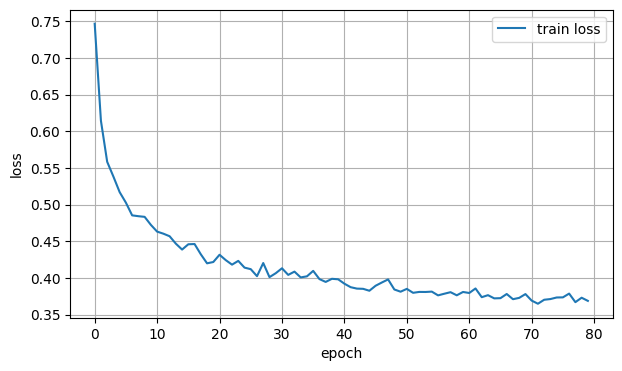

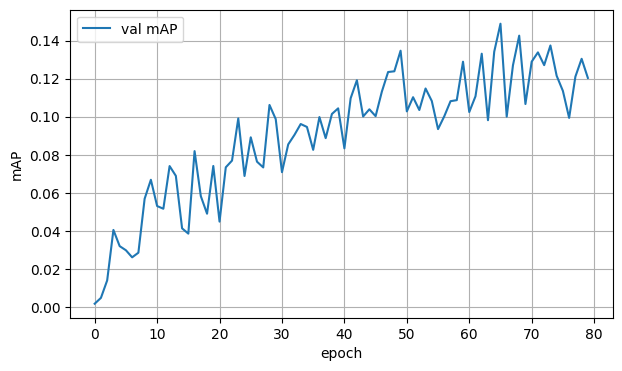

In [400]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,4))
plt.plot(train_losses, label="train loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(val_maps, label="val mAP")
plt.xlabel("epoch")
plt.ylabel("mAP")
plt.grid()
plt.legend()
plt.show()


на валидации лучшая модель определилась на 66й эпохе

In [398]:
model.load_state_dict(torch.load("best_model.pth", map_location=device))
model.eval()

detector(
  (backbone): backbone(
    (stem): Sequential(
      (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    )
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsamp

In [399]:
final_map = validate(model, test_dataloader, filter_predictions)
print("final mAP on test:", final_map)

final mAP on test: 0.11171425133943558


---

### final mAP on test: `0.11171425133943558`

---

Questions:

### Какой метод label assignment'a помогает лучше обучаться модели? Почему?
Тал работает лучше, чем классический max-IoU assignment. tal учит модель на тех anchor’ах, которые одновременно хорошо попадают в объект и уверенно относят его к правильному классу. поэтому модель сходится быстрее и выдаёт более чистые предсказания.

### Какое из сделаных вами улучшений внесло наибольший вклад в качество модели? Как вы думаете, почему это произошло?
наибольший вклад в рост качества модели внесли два улучшения:
переход на IoU-based регрессию (DIoU loss) , он напрямую оптимизирует перекрытие предсказанного бокса и GT, поэтому обучение стало стабильнее и точнее.

исправление координат (единый xyxy + отсутствие лишнего умножения на 640) - после этого модель перестала мимо учиться, предсказания стали корректными, и NMS начал работать как нужно.


### Какое из сделанных вами улучшений вообще не изменило метрику? Как вы думаете, почему это произошло?
улучшения, связанные с настройкой NMS (изменение порога IoU и score-threshold), практически не повлияли на итоговую метрику. это произошло потому, что качество самих предсказаний оставалось низким, и модель редко генерировала большое число перекрывающихся боксов. поэтому NMS просто нечего было оптимизировать